1 Importacion de librerias

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

2 Carga e Inspección de Datos

In [10]:
df = pd.read_csv('dataset_segmentacion_clientes.csv')

print("--- Primeros 5 registros ---")
print(df.head())

# Seleccionar solo las 5 características del negocio (excluyendo el ruido)
features = ['purchase_freq_month', 'avg_basket_usd', 'time_on_site_min', 'discount_sensitivity', 'returns_rate']
X = df[features]

--- Primeros 5 registros ---
   purchase_freq_month  avg_basket_usd  time_on_site_min  \
0            11.152508      181.300834         33.564036   
1            12.053451      178.637272         35.432081   
2             2.203006      450.185298          7.030757   
3             4.233314       89.006342         10.834453   
4             1.716799      449.773982          7.254548   

   discount_sensitivity  returns_rate  noise_gauss  noise_uniform  
0              1.000000      0.800000    -1.806578      -2.516905  
1              0.784974      0.000000     0.645129       2.115460  
2              0.898297      0.000000    -0.047406      -0.724173  
3              0.000000      0.800000     0.901700      -2.974026  
4              0.000000      0.003279     0.386013       2.424522  


3  Preprocesamiento (Escalado de Variables)

In [11]:
# K-Means utiliza distancias euclidianas, por lo que es imprescindible escalar
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

4 Método del Codo y Silhouette Score

c:\Users\USUARIO\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(
c:\Users\USUARIO\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(
c:\Users\USUARIO\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(
c:\Users\USUARIO\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak o

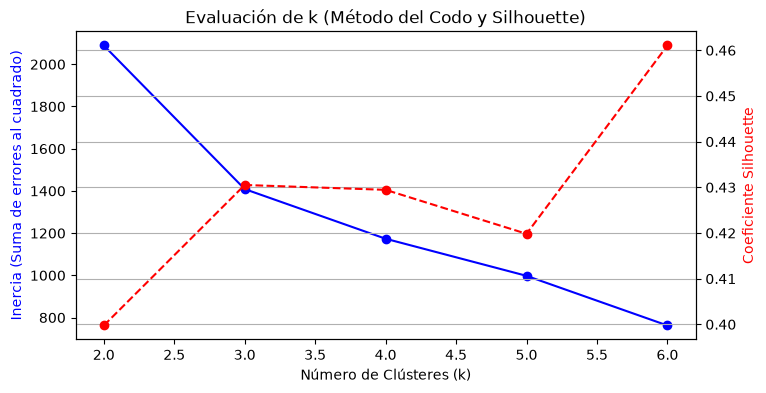

In [12]:
inertias = []
silhouettes = []
k_range = range(2, 7)

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_scaled, labels))

# Graficar el Método del Codo e Índice Silhouette
fig, ax1 = plt.subplots(figsize=(8, 4))

ax1.plot(k_range, inertias, 'bo-', label='Inercia (SSE)')
ax1.set_xlabel('Número de Clústeres (k)')
ax1.set_ylabel('Inercia (Suma de errores al cuadrado)', color='b')

ax2 = ax1.twinx()
ax2.plot(k_range, silhouettes, 'ro--', label='Silhouette Score')
ax2.set_ylabel('Coeficiente Silhouette', color='r')

plt.title('Evaluación de k (Método del Codo y Silhouette)')
plt.grid(True)
plt.show()

5 Entrenamiento con k=3

In [ ]:
# Del paso anterior la inecia se establece en 3 por el método del codo, y coeficiente silhuette mas alto, se usarán 3 clúteres
k_optimo = 3
kmeans_3 = KMeans(n_clusters=k_optimo, random_state=42, n_init=10)
df['cluster_k3'] = kmeans_3.fit_predict(X_scaled)

# Perfilado de segmentos para k=3
perfil_k3 = df.groupby('cluster_k3')[features].mean().round(2)
perfil_k3['clientes'] = df['cluster_k3'].value_counts().sort_index()
perfil_k3['porcentaje'] = (df['cluster_k3'].value_counts(normalize=True).sort_index() * 100).round(1)

print("\n--- PERFIL DE CLIENTES (k = 3) ---")
print(perfil_k3)



--- PERFIL DE CLIENTES (k = 3) ---
            purchase_freq_month  avg_basket_usd  time_on_site_min  \
cluster_k3                                                          
0                         11.96          180.00             35.02   
1                          1.85          450.12              5.97   
2                          4.09           89.96             10.00   

            discount_sensitivity  returns_rate  clientes  porcentaje  
cluster_k3                                                            
0                           0.54          0.33       230        32.9  
1                           0.36          0.38       250        35.7  
2                           0.38          0.30       220        31.4  


c:\Users\USUARIO\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(


6 Análisis de métricas

Interpretación paso a paso por cada valor de $k$:

$k = 2$ (Inercia: 2088.88 | Silhouette: 0.3997)
Análisis: Divide a los clientes en dos grandes bloques (ticket alto vs. ticket medio/bajo).
Conclusión: Aunque es simple, el Coeficiente Silhouette bajo ($0.3997$) muestra que es una simplificación excesiva que mezcla comportamientos muy distintos dentro del mismo grupo.

$k = 3$ (Inercia: 1408.70 | Silhouette: 0.4305) — PUNTO ÓPTIMO
Análisis:En el Método del Codo, entre $k=2$ y $k=3$ se produce el salto de caída de inercia más pronunciado (baja de 2088 a 1408).Alcanza un Silhouette Score máximo y estable ($0.4305$), lo que confirma que los 3 grupos están bien delimitados y son internamente homogéneos.
Conclusión: Es la mejor solución comercial y matemática: diferencia claramente a los Nativos Digitales Frecuentes, los Clientes VIP de Alto Ticket y los Compradores Ocasionales.

$k = 4$ (Inercia: 1173.44 | Silhouette: 0.4295)
Análisis: La reducción de la inercia comienza a aplanarse (ganancia marginal) y el Silhouette Score se mantiene casi idéntico al de $k=3$.Conclusión: En la práctica, $k=4$ toma al grupo VIP y lo divide en dos según la tasa de devoluciones. Aporta mayor granularidad, pero no mejora la estructura general del agrupamiento.

$k = 5$ (Inercia: 997.74 | Silhouette: 0.4198)
Análisis: La inercia sigue bajando, pero el Silhouette Score cae a $0.4198$.
Conclusión: Señal clara de sobre-fragmentación. Los grupos empiezan a solaparse entre sí y las fronteras se vuelven difusas.

$k = 6$ (Inercia: 762.47 | Silhouette: 0.4610)
Análisis: El Silhouette vuelve a subir debido a la formación de pequeños nichos muy compactos.
Conclusión: Aunque la métrica matemática suba, no aporta una mejora importante para tratar los grupos.
Para el equipo de marketing, gestionar 6 micro-segmentos resulta operativo y económicamente ineficiente en comparación con la claridad de 3 segmentos principales.

7 Perfilado e Interpretación Comercial de los Segmentos ($k = 3$)

Clúster 0: Nativos Digitales Frecuentes (32.9% de los clientes - 230 usuarios)
Comportamiento: Compras muy frecuentes (~12 al mes), ticket medio ($180 USD) y mayor permanencia en la web (~35 minutos).
Sensibilidad a Ofertas: Media-alta (0.54).
Estrategia Comercial: Programas de fidelización por puntos y recomendaciones personalizadas dentro del sitio para elevar el ticket promedio.

Clúster 1: Clientes VIP / Premium Esporádicos (35.7% de los clientes - 250 usuarios)
Comportamiento: Frecuencia baja (~1.8 compras/mes) pero con el ticket promedio más alto ($450 USD). Pasan muy poco tiempo navegando (~6 minutos), lo que indica compras directas y decididas.
Estrategia Comercial: Servicio de atención personalizada, envíos prioritarios y venta cruzada de productos de alta gama.

Clúster 2: Compradores Ocasionales de Ticket Bajo (31.4% de los clientes - 220 usuarios)
Comportamiento: Frecuencia moderada (~4 compras/mes), ticket bajo ($90 USD) y tiempo de permanencia medio (~10 minutos). Presentan la menor tasa de devoluciones (0.30).